# Deep Retention — Análisis exploratorio de datos

Análisis académico de `data/Customer-Churn-Records.csv`. El objetivo es
conocer la calidad, el desbalance y las relaciones relevantes antes del
preprocesamiento. Este notebook no modifica el CSV, no ajusta
transformadores y no entrena modelos.


## 1. Carga e inspección del dataset


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    candidate
    for candidate in [Path.cwd(), *Path.cwd().parents]
    if (candidate / "data" / "Customer-Churn-Records.csv").is_file()
)
DATA_PATH = PROJECT_ROOT / "data" / "Customer-Churn-Records.csv"

FEATURES = [
    "CreditScore", "Geography", "Age", "Tenure", "Balance",
    "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary",
]
TARGET = "Exited"

df = pd.read_csv(DATA_PATH)
print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")
display(df.head())
df.info()


Dimensiones: 10,000 filas × 18 columnas


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card 

### Función de las columnas

- **Predictoras iniciales del MLP:** las nueve variables de `FEATURES`.
- **Objetivo:** `Exited`.
- **Trazabilidad:** `RowNumber`, `CustomerId` y `Surname`.
- **Variables adicionales para diagnóstico:** `Gender`, `Complain`,
  `Satisfaction Score`, `Card Type` y `Point Earned`.

`Complain` se estudia de forma explícita por posible fuga de información,
pero no se incorpora al modelo. Las demás variables adicionales tampoco se
añaden automáticamente: primero debe confirmarse que estén disponibles antes
del abandono y que su uso sea adecuado.


## 2. Tipos, faltantes, duplicados y rangos


In [2]:
missing_by_column = df.isna().sum().rename("valores_nulos").to_frame()
display(missing_by_column)

quality_summary = pd.DataFrame(
    {
        "control": [
            "Filas duplicadas",
            "CustomerId duplicados",
            "RowNumber duplicados",
            "Apellidos con ?",
        ],
        "cantidad": [
            int(df.duplicated().sum()),
            int(df["CustomerId"].duplicated().sum()),
            int(df["RowNumber"].duplicated().sum()),
            int(df["Surname"].astype("string").str.contains("?", regex=False, na=False).sum()),
        ],
    }
)
display(quality_summary)

numeric_columns = df.select_dtypes(include=np.number).columns
ranges = df[numeric_columns].agg(["min", "max"]).T
display(ranges)

binary_columns = ["HasCrCard", "IsActiveMember", "Exited", "Complain"]
binary_domains = pd.DataFrame(
    {
        "variable": binary_columns,
        "valores_observados": [
            sorted(df[column].dropna().unique().tolist())
            for column in binary_columns
        ],
        "dominio_valido": [
            set(df[column].dropna().unique()).issubset({0, 1})
            for column in binary_columns
        ],
    }
)
display(binary_domains)


,valores_nulos
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


,control,cantidad
0,Filas duplicadas,0
1,CustomerId duplicados,0
2,RowNumber duplicados,0
3,Apellidos con ?,92


,min,max
RowNumber,1.00,10000.00
CustomerId,15565701.00,15815690.00
CreditScore,350.00,850.00
Age,18.00,92.00
Tenure,0.00,10.00
Balance,0.00,250898.09
NumOfProducts,1.00,4.00
HasCrCard,0.00,1.00
IsActiveMember,0.00,1.00
EstimatedSalary,11.58,199992.48


,variable,valores_observados,dominio_valido
0,HasCrCard,"[0, 1]",True
1,IsActiveMember,"[0, 1]",True
2,Exited,"[0, 1]",True
3,Complain,"[0, 1]",True


**Interpretación.** El archivo contiene 10.000 clientes y 18 columnas,
sin valores faltantes, filas duplicadas ni identificadores repetidos. Las
variables binarias usan únicamente 0 y 1 y los rangos observados son
plausibles. Se detectan 92 apellidos con `?`; no afectan al MLP porque
`Surname` no es predictor. Su tratamiento se realizará sobre una copia en
el notebook 02, sin inventar nombres ni eliminar clientes.


## 3. Distribución de `Exited` y desbalance


,cantidad,porcentaje
Exited,,
0,7962,79.62
1,2038,20.38


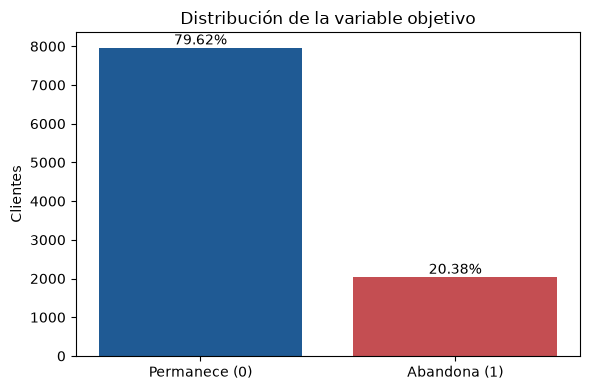

In [3]:
target_distribution = df[TARGET].value_counts().sort_index().to_frame("cantidad")
target_distribution["porcentaje"] = (
    target_distribution["cantidad"] / len(df) * 100
)
display(target_distribution)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Permanece (0)", "Abandona (1)"], target_distribution["cantidad"], color=["#1F5A94", "#C44E52"])
ax.bar_label(bars, labels=[f"{value:.2f}%" for value in target_distribution["porcentaje"]])
ax.set_ylabel("Clientes")
ax.set_title("Distribución de la variable objetivo")
plt.tight_layout()
plt.show()


**Interpretación.** El 20,38 % de los clientes abandonó y el 79,62 %
permaneció. La relación cercana a 4:1 justifica particiones estratificadas,
métricas sensibles a la clase minoritaria y tratamiento del desbalance en
el entrenamiento. La exactitud por sí sola no será suficiente.


## 4. Estadísticas y distribuciones de las predictoras


,count,mean,std,min,25%,50%,75%,max
CreditScore,10000.0,650.528800,96.653299,350.00,584.00,652.000,718.0000,850.00
Age,10000.0,38.921800,10.487806,18.00,32.00,37.000,44.0000,92.00
Tenure,10000.0,5.012800,2.892174,0.00,3.00,5.000,7.0000,10.00
Balance,10000.0,76485.889288,62397.405202,0.00,0.00,97198.540,127644.2400,250898.09
NumOfProducts,10000.0,1.530200,0.581654,1.00,1.00,1.000,2.0000,4.00
HasCrCard,10000.0,0.705500,0.455840,0.00,0.00,1.000,1.0000,1.00
IsActiveMember,10000.0,0.515100,0.499797,0.00,0.00,1.000,1.0000,1.00
EstimatedSalary,10000.0,100090.239881,57510.492818,11.58,51002.11,100193.915,149388.2475,199992.48


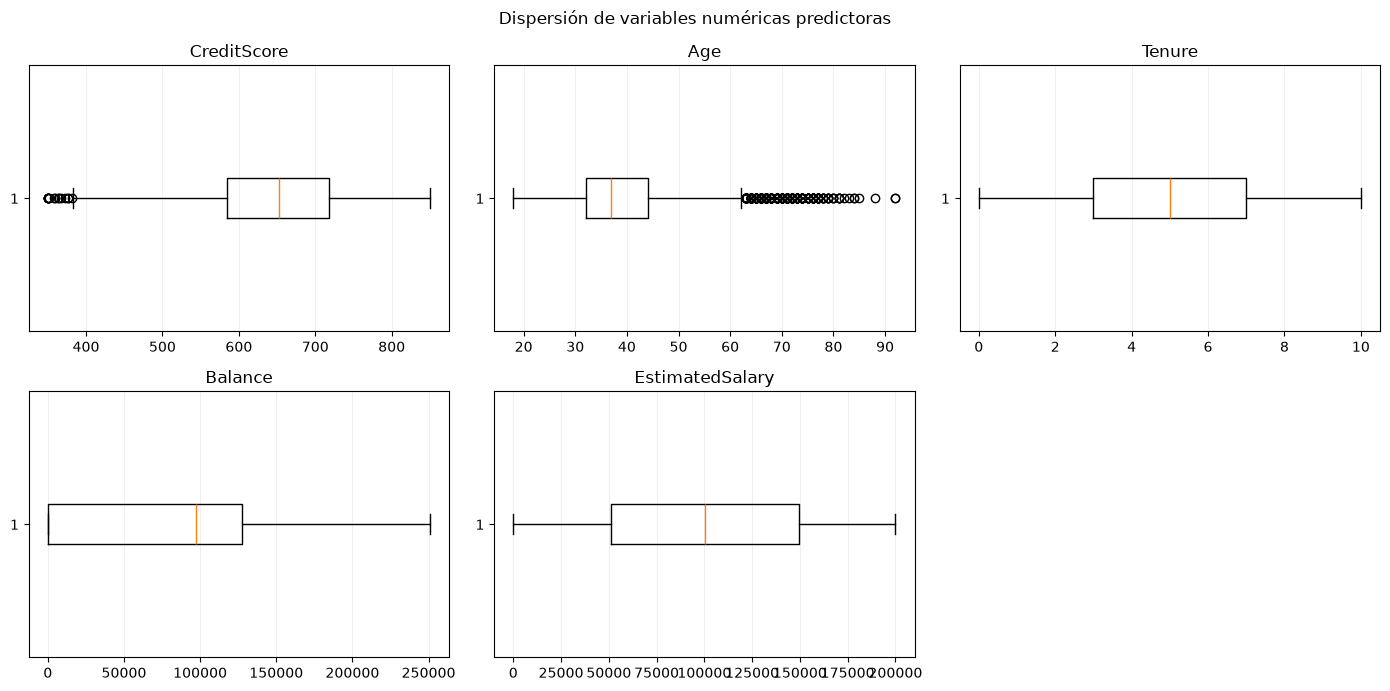

,condición,clientes,porcentaje
0,Balance = 0,3617,36.17
1,Balance > 0,6383,63.83


In [4]:
numeric_predictors = [column for column in FEATURES if column != "Geography"]
continuous_predictors = [
    "CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary"
]
display(df[numeric_predictors].describe().T)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for axis, column in zip(axes.flat, continuous_predictors):
    axis.boxplot(df[column].dropna(), orientation="horizontal")
    axis.set_title(column)
    axis.grid(axis="x", alpha=0.2)
axes.flat[-1].axis("off")
fig.suptitle("Dispersión de variables numéricas predictoras")
plt.tight_layout()
plt.show()

balance_zero = int(df["Balance"].eq(0).sum())
display(
    pd.DataFrame(
        {
            "condición": ["Balance = 0", "Balance > 0"],
            "clientes": [balance_zero, len(df) - balance_zero],
            "porcentaje": [
                balance_zero / len(df) * 100,
                (len(df) - balance_zero) / len(df) * 100,
            ],
        }
    )
)


**Interpretación.** Las escalas numéricas son muy diferentes, por lo que
las variables continuas requerirán escalado ajustado solo con entrenamiento.
Los diagramas de caja señalan valores extremos principalmente en `Age` y
`CreditScore`, pero estar fuera de los bigotes no demuestra que sean datos
erróneos. El 36,17 % presenta saldo cero; es un valor válido y se conservará.


## 5. Variables adicionales y riesgo de fuga de información


In [5]:
complain_cross = pd.crosstab(
    df["Complain"], df["Exited"], margins=True
)
display(complain_cross)
complain_match = float(df["Complain"].eq(df["Exited"]).mean())
print(f"Coincidencia Complain = Exited: {complain_match:.2%}")

grouped_tables = []
for column in ["Gender", "Card Type", "Satisfaction Score"]:
    table = (
        df.groupby(column, observed=False)[TARGET]
        .agg(clientes="size", tasa_abandono="mean")
        .reset_index()
        .rename(columns={column: "categoría"})
    )
    table.insert(0, "variable", column)
    table["tasa_abandono"] *= 100
    grouped_tables.append(table)
display(pd.concat(grouped_tables, ignore_index=True))

point_summary = df.groupby(TARGET)["Point Earned"].agg(
    clientes="size", media="mean", mediana="median", desviación="std"
)
display(point_summary)


Exited,0,1,All
Complain,,,
0,7952,4,7956
1,10,2034,2044
All,7962,2038,10000


Coincidencia Complain = Exited: 99.86%


,variable,categoría,clientes,tasa_abandono
0,Gender,Female,4543,25.071539
1,Gender,Male,5457,16.474253
2,Card Type,DIAMOND,2507,21.779019
3,Card Type,GOLD,2502,19.264588
4,Card Type,PLATINUM,2495,20.360721
5,Card Type,SILVER,2496,20.112179
6,Satisfaction Score,1,1932,20.031056
7,Satisfaction Score,2,2014,21.797418
8,Satisfaction Score,3,2042,19.637610
9,Satisfaction Score,4,2008,20.617530


,clientes,media,mediana,desviación
Exited,,,,
0,7962,607.044084,603.0,226.091682
1,2038,604.448479,610.5,225.315301


**Interpretación.** `Complain` coincide con `Exited` en el 99,86 % de los
registros: solo 14 clientes difieren. Esta relación casi determinista puede
significar que la queja se registró después o como consecuencia del abandono.
Incluirla produciría una fuga de información y métricas artificialmente altas,
por lo que se excluye del MLP.

`Gender`, `Satisfaction Score`, `Card Type` y `Point Earned` aportan contexto,
pero el archivo no documenta el momento exacto de su captura. El modelo inicial
conserva las nueve características aprobadas; una ampliación futura requerirá
confirmar disponibilidad previa al abandono y revisar implicaciones de equidad.


## 6. Correlaciones relevantes


,correlación_con_Exited
IsActiveMember,-0.156356
NumOfProducts,-0.047611
CreditScore,-0.026771
Tenure,-0.013656
HasCrCard,-0.006976
EstimatedSalary,0.012490
Balance,0.118577
Age,0.285296


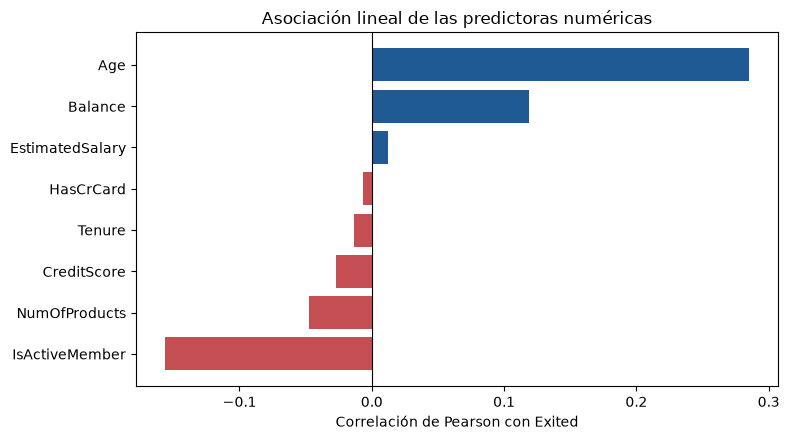

In [6]:
target_correlations = (
    df[numeric_predictors + [TARGET]]
    .corr(method="pearson")[TARGET]
    .drop(TARGET)
    .sort_values()
)
display(target_correlations.rename("correlación_con_Exited").to_frame())

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#C44E52" if value < 0 else "#1F5A94" for value in target_correlations]
ax.barh(target_correlations.index, target_correlations.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlación de Pearson con Exited")
ax.set_title("Asociación lineal de las predictoras numéricas")
plt.tight_layout()
plt.show()


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
CreditScore,1.000,-0.004,0.001,0.006,0.012,-0.005,0.026,-0.001,-0.027
Age,-0.004,1.000,-0.010,0.028,-0.031,-0.012,0.085,-0.007,0.285
Tenure,0.001,-0.010,1.000,-0.012,0.013,0.023,-0.028,0.008,-0.014
Balance,0.006,0.028,-0.012,1.000,-0.304,-0.015,-0.010,0.013,0.119
NumOfProducts,0.012,-0.031,0.013,-0.304,1.000,0.003,0.010,0.014,-0.048
HasCrCard,-0.005,-0.012,0.023,-0.015,0.003,1.000,-0.012,-0.010,-0.007
IsActiveMember,0.026,0.085,-0.028,-0.010,0.010,-0.012,1.000,-0.011,-0.156
EstimatedSalary,-0.001,-0.007,0.008,0.013,0.014,-0.010,-0.011,1.000,0.012
Exited,-0.027,0.285,-0.014,0.119,-0.048,-0.007,-0.156,0.012,1.000


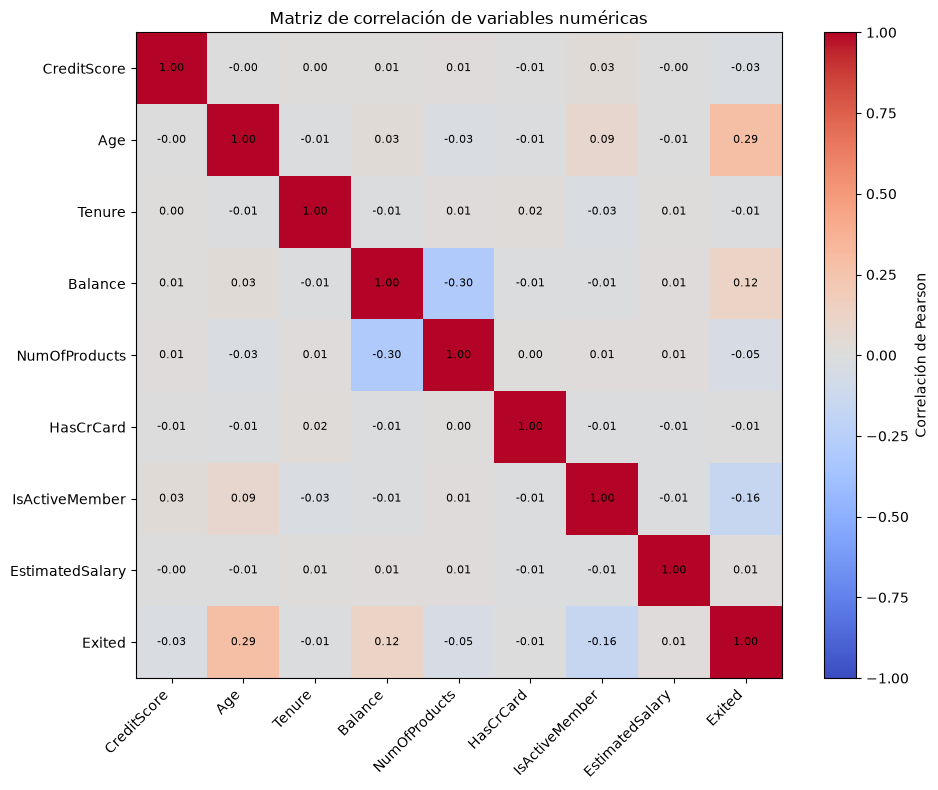

,Correlación con Exited
Age,0.285296
Balance,0.118577
EstimatedSalary,0.012490
HasCrCard,-0.006976
Tenure,-0.013656
CreditScore,-0.026771
NumOfProducts,-0.047611
IsActiveMember,-0.156356


In [7]:

# Matriz de correlación de las variables numéricas
numeric_predictors = [
    column for column in FEATURES
    if pd.api.types.is_numeric_dtype(df[column])
]

correlation_columns = numeric_predictors + [TARGET]

correlation_matrix = df[correlation_columns].corr(
    method="pearson"
)

# Mostrar matriz numérica
display(correlation_matrix.round(3))

# Representación gráfica
fig, ax = plt.subplots(figsize=(10, 8))

heatmap = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlation_columns)))
ax.set_yticks(range(len(correlation_columns)))

ax.set_xticklabels(correlation_columns, rotation=45, ha="right")
ax.set_yticklabels(correlation_columns)

# Mostrar coeficientes dentro de cada celda
for i in range(len(correlation_columns)):
    for j in range(len(correlation_columns)):
        ax.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(heatmap, ax=ax, label="Correlación de Pearson")
ax.set_title("Matriz de correlación de variables numéricas")

plt.tight_layout()
plt.show()

# Correlaciones con el abandono
display(
    correlation_matrix[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
    .to_frame("Correlación con Exited")
)


**Interpretación.** `Age` presenta la mayor asociación lineal positiva con
el abandono, seguida por `Balance`; `IsActiveMember` muestra la asociación
negativa más destacada. Las demás correlaciones lineales son pequeñas. Esto
no vuelve inútiles las variables: una MLP puede aprender interacciones y
relaciones no lineales. No se elimina ninguna característica solo por su
correlación individual.


## 7. Conclusiones y recomendaciones

- El dataset correcto contiene 10.000 clientes y 18 columnas, sin faltantes,
  duplicados ni identificadores repetidos.
- Los 92 apellidos con `?` deben representarse como desconocidos sobre una
  copia, sin eliminar clientes ni alterar `CustomerId`.
- `Exited` está desbalanceada; se requieren división estratificada y métricas
  ROC-AUC, PR-AUC, Brier, precisión, recall y F1.
- Los saldos cero son válidos y no se eliminarán. Los posibles valores atípicos
  se conservarán salvo evidencia de error.
- `Complain` queda excluida por riesgo evidente de *data leakage*.
- Las nueve predictoras iniciales se mantendrán para un flujo simple y compatible.
- El escalado y la codificación se ajustarán únicamente con entrenamiento,
  después de dividir los conjuntos.
